# مرحلهٔ ۳ — امتیازدهی اعتباری: هزینهٔ تصمیم، نه دقت

این نوت‌بوک فقط از دیتابیس می‌خواند (SQLAlchemy، بدون ``read_csv``). فایل خام از همان خط لولهٔ مرحلهٔ ۱ وارد ``credit.application`` شده و کدهای sentinel در ``credit.v_model_input`` به NULL تبدیل شده‌اند؛ یعنی همان آماده‌سازی روی فایل تازهٔ ماه بعد اعمال می‌شود.

هر عددی که در ادامه چاپ می‌شود در ``data/curated/credit_evidence.json`` هم نوشته می‌شود و ``report.md`` مجاز است فقط از همان اعداد نقل کند (سلول آخر این را چک می‌کند).

**زمان:** اگر به سقف ۲۰ دقیقه نزدیک شدیم، ``RUN_LIGHT = True`` فولدها را از ۵ به ۳ کم می‌کند؛ این یک تخمین است، نه عدد اندازه‌گیری‌شده.

**خروجی‌های این فایل:** از اجرای کامل ``Run All`` روی PostgreSQL ۱۶ و یک دادهٔ fixture آزمایشی (۱۵۰٬۰۰۰ ردیف تولید‌شده، نه فایل Kaggle) نوشته شده‌اند تا نشان دهند ماشین‌افزار از سر تا پا کار می‌کند؛ این‌ها نتیجهٔ چالش نیستند. برای اعداد واقعی، همین نوت‌بوک را روی دیتابیس خودتان با فایل اصلی Run All کنید - خروجی‌های تازه جای همین‌ها را می‌گیرند.

| # | بخش | معیار پذیرش |
|---|---|---|
| ۱ | ممیزی نشتی زمان-تصمیم | اولین بخش |
| ۲ | ساختار، sentinel، گم‌شدگی | سیاست با عدد، ≥۲ سیاست imputation |
| ۳ | split و prep | مرز قابل بازرسی |
| ۴ | فیچرهای مهندسی‌شده | ≥۴ فیچر، با/بدون اندازه‌گیری شد |
| ۵ | بیس‌لاین و دو خانواده | ≥۲۵٪ کاهش هزینه |
| ۶ | آستانه از منحنی هزینه | هرگز ۰٫۵، حساسیت ۱۲:۱→۴:۱ |
| ۷ | ارزیابی کامل + holdout یک‌بار | ماتریس اختلاط، spread، فاصلهٔ CV |
| ۸ | Model Card، importance، fairness | سطر به سطر از عدد |
| ۹ | آرتیفکت‌ها | باندل + اسکریپت پیش‌بینی |


In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))
import pandas as pd

from credit import columns, cost, db, evaluate, features, measure, missingness, models, prep, read, report, split, tables
from credit.config import load_credit_config
from credit.predict import score_file
from data_factory.manifest import code_version

SEED = 20261103
RUN_LIGHT = False
engine = db.engine_for(Path("../stage-1/config/default.toml"))
credit_cfg = load_credit_config(Path("config/credit.toml"))
print(f"seed={SEED} light={RUN_LIGHT} schema={credit_cfg.schema} code={code_version()}")


seed=20261103 light=False schema=credit code=unknown


## ۰. داده‌ای که می‌خوانیم، از کجا آمده

پیش از هر تحلیل، ردیف‌های نوت‌بوک باید همان ردیف‌هایی باشند که loader تأیید کرده. ``credit.load_run`` نام فایل، sha256، تعداد بارگذاری‌شده و تعداد رد شده را نگه می‌دارد.

In [2]:
provenance = measure.load_run_provenance(engine, schema=credit_cfg.schema)
rows_view = read.row_count(engine, "input", schema=credit_cfg.schema)
rows_raw = read.row_count(engine, "raw", schema=credit_cfg.schema)
print("| field | value |\n|---|---|")
for key, value in provenance.items():
    print(f"| `{key}` | {value} |")
print(f"| rows_in_view | {rows_view} |\n| rows_in_table | {rows_raw} |")
assert rows_view == rows_raw, "the view must not add or drop rows"
assert int(provenance["rows_loaded"]) == rows_view, "load_run and the table disagree"
print(f"provenance ok: {rows_view} rows, sha256 {str(provenance['sha256'])[:12]}")


| field | value |
|---|---|
| `source_kind` | file |
| `file_name` | cs-training.csv |
| `sha256` | 026a9163cc6f40092627d66ed837ae63b2cf83d4b4c15ebbefa419a727121330 |
| `rows_loaded` | 150000 |
| `rejected_count` | 0 |
| `fingerprint` | e9eb3b094a62 |
| `loaded_at` | 2026-11-04 03:27:24.692725+00:00 |
| rows_in_view | 150000 |
| rows_in_table | 150000 |
provenance ok: 150000 rows, sha256 026a9163cc6f


## ۱. ممیزی نشتی در زمان تصمیم — اولین بخش گزارش

دو پرسش جدا: آیا فیچر در لحظهٔ تصمیم در دسترس است (نه فقط در دادهٔ تاریخی)، و آیا عددی که برای ساختش لازم است از ردیف‌های ارزیابی آمده؟ ستون آخر جدول، مرزی است که هر فیچر را کنترل می‌کند؛ ثابت‌های برازش‌شده هم جداگانه در بخش prep لیست می‌شوند.

In [3]:
audit = features.audit_table()
tables.md_table(print(audit))
unavailable = audit.loc[audit["available before the decision"] == "NO", "feature"].tolist()
print(f"\nnot available at decision time: {unavailable or 'none'}")
assert not unavailable, "a feature unavailable at decision time cannot be used"
needs_evidence = audit.loc[audit["needs evidence"] != "-", ["feature", "needs evidence"]]
print(f"\n{tables.md_table(needs_evidence) if len(needs_evidence) else 'no feature claims evidence it does not carry'}")


                    feature                                    built from  \
0  delinquency_events_total   num_late_30_59, num_late_90, num_late_60_89   
1    utilization_over_limit               revolving_utilization_unsecured   
2      income_per_dependent                monthly_income, num_dependents   
3             overcommitted                                    debt_ratio   
4     recent_exposure_total  num_open_credit_lines, num_real_estate_loans   
5       income_not_reported                                monthly_income   

                                          hypothesis  \
0  any recorded past-due event matters, not only ...   
1  reported utilisation above 100% is not a measu...   
2  income alone ignores burden; income per head o...   
3  debt ratio past 1.0 means scheduled payments e...   
4  a thin file - few lines of any kind - predicts...   
5  if missingness carries information, the absenc...   

  available before the decision  \
0                           yes 

## ۲. مقادیر غیرعادی: کد یا عدد؟

همین شمارش مستقل روی جدول خام، در SQL و در پایتون گرفته می‌شود؛ برابریشان یعنی سیاست sentinel که در view نوشته شده، همان چیزی است که کد هم اعمال می‌کند - و این همان شرط «prep بدون تغییر روی فایل تازه اعمال می‌شود» است. شمارش از view گرفته نمی‌شود، چون view دقیقاً همان کدها را NULL می‌کند و صفرِ دیدن از view مدرک نیست. جفت‌هایی که کاوش شدند و چیزی پیدا نشد هم سطر می‌مانند: صفرِ اندازه‌گیری‌شده مدرک است، سطرِ نبودن نه.

In [4]:
spikes_sql = measure.run_query(engine, "sentinel_spikes", sql_dir=Path("sql"))
raw = read.load_frame(engine, "raw", schema=credit_cfg.schema)
spikes_py = features.sentinel_spike_counts(raw)
tables.md_table(print(spikes_sql))
print(f"\nsql rows={len(spikes_sql)} python rows={len(spikes_py)}")
tables.md_table(print(spikes_py))


      column_name  code  rows_with_code  rows_total pct_of_file  \
0  num_late_30_59    96           24974      150000     16.6493   
1  num_late_30_59    98           24712      150000     16.4747   
2  num_late_60_89    96           29842      150000     19.8947   
3  num_late_60_89    98               0      150000      0.0000   
4     num_late_90    96               0      150000      0.0000   
5     num_late_90    98           24907      150000     16.6047   

  default_rate_with_code default_rate_otherwise default_rate_overall  
0                0.08056                0.07620              0.07693  
1                0.07587                0.07713              0.07693  
2                0.07607                0.07714              0.07693  
3                   None                0.07693              0.07693  
4                   None                0.07693              0.07693  
5                0.07821                0.07667              0.07693  

sql rows=6 python rows=6
       

'|  |\n||'

In [5]:
# two independent counts of the same thing must agree row for row, not just in length
merged = spikes_sql.merge(
    spikes_py[["column", "code", "rows"]],
    left_on=["column_name", "code"],
    right_on=["column", "code"],
    how="outer",
    indicator=True,
)
assert (merged["_merge"] == "both").all(), "the two sides probed different (column, code) pairs"
counts = merged["rows_with_code"].astype("int64")
assert (counts == merged["rows"].astype("int64")).all(), "SQL and pandas counted different rows"
print(f"\npolicy: {sorted(columns.SENTINEL_CODES)} -> NULL in the view, kept verbatim in the table")
zeros = int((merged['rows'] == 0).sum())
print(f"probed pairs={len(merged)}, measured zeros={zeros} (a measured zero is evidence; an absent row is not)")



policy: [96, 98] -> NULL in the view, kept verbatim in the table
probed pairs=6, measured zeros=2 (a measured zero is evidence; an absent row is not)


In [6]:
frame = read.load_frame(engine, "input", schema=credit_cfg.schema)
frame = features.build_features(frame)
print(f"rows={len(frame)} columns={len(frame.columns)} target_rate={frame[columns.VIEW_TARGET_COLUMN].mean():.6f}")
print("\ndtypes:")
print(tables.md_table(frame.dtypes.to_frame("dtype").reset_index(names="column")))
counts = ["num_real_estate_loans", "num_dependents", "num_late_90"]
print("\ninteger-valued and numeric-looking, kept as counts: " + ", ".join(counts))
print("why not one-hot: each is ordered and zero is a real value; binning would only cost degrees of freedom")


rows=150000 columns=20 target_rate=0.076927

dtypes:
| column | dtype |
| --- | --- |
| row_id | int64 |
| serious_dlqin_2yrs | int64 |
| revolving_utilization_unsecured | float64 |
| utilization_capped | float64 |
| age | float64 |
| num_late_30_59 | float64 |
| num_late_90 | float64 |
| num_late_60_89 | float64 |
| debt_ratio | float64 |
| monthly_income | float64 |
| income_missing | int64 |
| num_open_credit_lines | float64 |
| num_real_estate_loans | float64 |
| num_dependents | float64 |
| delinquency_events_total | float64 |
| utilization_over_limit | float64 |
| income_per_dependent | float64 |
| overcommitted | float64 |
| recent_exposure_total | float64 |
| income_not_reported | float64 |

integer-valued and numeric-looking, kept as counts: num_real_estate_loans, num_dependents, num_late_90
why not one-hot: each is ordered and zero is a real value; binning would only cost degrees of freedom


## ۳. گم‌شدگی: آیا عدد دارد و سیاست را عوض می‌کند؟

پاسخ این بخش باید سیاست را عوض کند، وگرنه فقط توصیف است. دو سیاست imputation در ``prep.PLANS`` با هم مقایسه می‌شوند و معیارشان هزینهٔ کراس‌والید است، نه شکل توزیع.

In [7]:
parity = measure.run_query(engine, "missingness_parity", sql_dir=Path("sql"))
tables.md_table(print(parity))
profile = missingness.missingness_profile(frame, tuple(columns.MODEL_FEATURE_COLUMNS))
print(f"\n{tables.md_table(profile)}")
no_income = frame["income_missing"] == 1
a, b = frame[no_income], frame[~no_income]
test = missingness.two_proportion_test(int(a[columns.VIEW_TARGET_COLUMN].sum()), len(a), int(b[columns.VIEW_TARGET_COLUMN].sum()), len(b))
print(f"\nincome reported vs not: {json.dumps(test, default=str)}")


                       column_name  rows_total  missing_rows missing_pct  \
0                   monthly_income      150000         21429     14.2860   
1                   num_dependents      150000         16667     11.1113   
2                              age      150000          5173      3.4487   
3                       debt_ratio      150000             0      0.0000   
4                   num_late_30_59      150000             0      0.0000   
5                   num_late_60_89      150000             0      0.0000   
6                      num_late_90      150000             0      0.0000   
7            num_open_credit_lines      150000             0      0.0000   
8            num_real_estate_loans      150000             0      0.0000   
9  revolving_utilization_unsecured      150000             0      0.0000   

  default_rate_when_missing default_rate_otherwise difference  
0                   0.07695                0.07692    0.00003  
1                   0.07698        

In [8]:
splits = split.stratified_split(frame, seed=SEED)
tables.md_table(print(split.boundary_audit(splits)))
feature_names = tuple(spec.name for spec in features.FEATURES)
# prep owns the missingness flags, so the list handed to fit() is what the frame
# already holds: raw model columns plus the engineered ones, never a flag
fit_columns = tuple(columns.MODEL_FEATURE_COLUMNS) + feature_names
fitted = {name: prep.fit(splits.train, plan=plan, columns=fit_columns) for name, plan in prep.PLANS.items()}
train_y = prep.target(splits.train)
for name, stats in fitted.items():
    assert stats.fitted_rows == len(splits.train), f"{name} saw rows outside train"
print(f"\nplans compared: {sorted(fitted)}")


        split   rows  positives  positive_rate  overlap_with_train
0       train  90000       6923       0.076922                   0
1  validation  30000       2308       0.076933                   0
2     holdout  30000       2308       0.076933                   0

plans compared: ['median+indicator', 'median+no-indicator', 'zero+none']


In [9]:
chosen = fitted["median+indicator"]
tables.md_table(print(prep.audit(chosen)))
prepared_val = prep.apply(splits.validation, chosen)
left = prep.remaining_missing(prepared_val, list(chosen.feature_names()))
print(f"\nNaN left after preparation: {int(left['nan_after_prep'].sum())}")
assert int(left["nan_after_prep"].sum()) == 0, "preparation must leave no NaN for the linear model"
print("every number above came from the train split; apply() has no access to any other frame")


                                  column                          statistic  \
0        revolving_utilization_unsecured  median+indicator imputation value   
1                                    age  median+indicator imputation value   
2                         num_late_30_59  median+indicator imputation value   
3                             debt_ratio  median+indicator imputation value   
4                         monthly_income  median+indicator imputation value   
5                  num_open_credit_lines  median+indicator imputation value   
6                            num_late_90  median+indicator imputation value   
7                  num_real_estate_loans  median+indicator imputation value   
8                         num_late_60_89  median+indicator imputation value   
9                         num_dependents  median+indicator imputation value   
10              delinquency_events_total  median+indicator imputation value   
11                utilization_over_limit  median+ind


NaN left after preparation: 0
every number above came from the train split; apply() has no access to any other frame


## ۴. فیچرهای مهندسی‌شده: هر کدام با یک فرضیه، و اندازه‌گیری با/بدون

فیچری که هزینه را کم نمی‌کند حذف می‌شود و در گزارش ذکر می‌شود؛ نگه داشتنش «بی‌ضرر» نیست، چون یک خط ممیزی نشتی و یک ستون مرور اضافه می‌کند.

In [10]:
k = 3 if RUN_LIGHT else 5
folds = split.stratified_folds(splits.train, seed=SEED, k=k)
sweep = []
for name, stats in fitted.items():
    X = prep.apply(splits.train, stats)[list(stats.feature_names())]
    sweep.append(models.cross_validate_cost("logistic", X, train_y, folds, plan=name))
print(f"k={k} folds, plan sweep on the fast family:")
tables.md_table(print(models.compare(sweep)))
best_plan = min(sweep, key=lambda r: r.mean_cost).plan
print(f"\nbest plan by mean cost: {best_plan}")


/tmp/v3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/tmp/v3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/tmp/v3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/tmp/v3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/tmp/v3/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


k=5 folds, plan sweep on the fast family:
     family                 plan matrix  mean_cost  std_cost  worst_cost  \
0  logistic     median+indicator   12:1    909.900     6.492     919.440   
1  logistic  median+no-indicator   12:1    914.356     7.008     922.718   
2  logistic            zero+none   12:1    915.656     4.175     919.440   

   mean_auc  threshold_std  
0    0.5039         0.0055  
1    0.5010         0.0147  
2    0.4971         0.0091  

best plan by mean cost: median+indicator


In [11]:
final_stats = fitted[best_plan]
names = list(final_stats.feature_names())
X_train = prep.apply(splits.train, final_stats)[names]
families = []
for family in models.FAMILIES:
    families.append(models.cross_validate_cost(family, X_train, train_y, folds, plan=best_plan))
table = models.compare(sweep + families)
tables.md_table(print(table))
best = models.pick_best(sweep + families)
print(f"\nselected {best.family} / {best.plan}: mean {best.mean_cost:.2f} std {best.std_cost:.2f} worst {best.worst_cost:.2f}")


          family                 plan matrix  mean_cost  std_cost  worst_cost  \
0       logistic     median+indicator   12:1    909.900     6.492     919.440   
1       logistic     median+indicator   12:1    909.900     6.492     919.440   
2       logistic  median+no-indicator   12:1    914.356     7.008     922.718   
3       logistic            zero+none   12:1    915.656     4.175     919.440   
4  boosted_trees     median+indicator   12:1    916.845     5.045     921.996   

   mean_auc  threshold_std  
0    0.5039         0.0055  
1    0.5039         0.0055  
2    0.5010         0.0147  
3    0.4971         0.0091  
4    0.4980         0.0045  

selected logistic / median+indicator: mean 909.90 std 6.49 worst 919.44


In [12]:
ablation = []
for spec in features.FEATURES:
    kept = [name for name in names if name != spec.name]
    result = models.cross_validate_cost(best.family, prep.apply(splits.train, final_stats)[kept], train_y, folds, plan=f"without {spec.name}")
    ablation.append({"feature": spec.name, "mean_cost": round(result.mean_cost, 3), "delta": round(result.mean_cost - best.mean_cost, 3)})
ablation_frame = pd.DataFrame(ablation).sort_values("delta", ascending=False)
full_cost = next(r.mean_cost for r in families if r.family == best.family)
print(f"full model (all {len(names)} features): cost {full_cost:.3f}\n")
tables.md_table(print(ablation_frame))


full model (all 24 features): cost 909.900

                    feature  mean_cost  delta
2      income_per_dependent    914.178  4.278
3             overcommitted    912.778  2.878
1    utilization_over_limit    912.578  2.678
4     recent_exposure_total    912.567  2.667
5       income_not_reported    910.678  0.778
0  delinquency_events_total    910.600  0.700


'|  |\n||'

**تصمیم:** فیچری که حذفش هزینهٔ میانگین را بالا نمی‌برد از ماتریس نهایی بیرون می‌ماند. آبلیشن تک‌به‌تک است، پس مجموعهٔ حذف‌ها جدا اندازه‌گیری می‌شود؛ مدل نهایی، آستانه و CVِ گزارش‌شده همه روی همین ماتریس محاسبه می‌شوند - وگرنه «حذف شد» فقط یک جمله در خروجی است.

In [13]:
ablation_rows = int((ablation_frame["delta"] <= 0).sum())
dropped = ablation_frame.loc[ablation_frame["delta"] <= 0, "feature"].tolist()
print(f"\nfeatures that did not pay and are dropped from the final matrix: {dropped or 'none'}")
kept_names = [name for name in names if name not in dropped]
kept_inputs = tuple(name for name in fit_columns if name not in dropped)
X_kept = prep.apply(splits.train, final_stats)[kept_names]
kept_cv = models.cross_validate_cost(
    best.family, X_kept, train_y, folds, plan=f"{best_plan} without the {len(dropped)}"
)
print(
    f"cv on the kept matrix ({len(kept_names)} columns): mean {kept_cv.mean_cost:.2f}"
    f" +/- {kept_cv.std_cost:.2f}; full matrix was {best.mean_cost:.2f}"
)



features that did not pay and are dropped from the final matrix: none


cv on the kept matrix (24 columns): mean 909.90 +/- 6.49; full matrix was 909.90


## ۵. بیس‌لاین بدون یادگیری، و هزینهٔ زمین

قبل از هر ادعایی دربارهٔ مدل، کف زمین: «هیچ‌کس را علامت نزن» و «همه را علامت بزن» و یک قانون سادهٔ بدون مدل. معیار پذیرش ۲۵٪ کاهش نسبت به اولی است.

In [14]:
val_y = prep.target(splits.validation)
baselines = evaluate.baseline_costs(val_y)
rule_flags = (splits.validation["utilization_over_limit"] > 0).astype("int64")
rule = cost.rule_baseline(val_y, rule_flags, name="utilization-over-limit")
entries = {**{name: {"cost_per_1000": value, "counts": {}} for name, value in baselines.items()}, rule["name"]: rule}
for name, entry in entries.items():
    print(f"| baseline {name} | cost {entry['cost_per_1000']:.2f} per 1,000 |")
floor = baselines["flag-nobody"]
print(f"\nfloor to beat: {floor:.2f}; 25% reduction means < {floor * 0.75:.2f}")


| baseline flag-nobody | cost 923.20 per 1,000 |
| baseline flag-everybody | cost 923.07 per 1,000 |
| baseline utilization-over-limit | cost 920.20 per 1,000 |

floor to beat: 923.20; 25% reduction means < 692.40


## ۶. آستانه: از منحنی هزینه روی validation

هرگز ۰٫۵ - آن عدد یک ادعا دربارهٔ برابر بودن هزینهٔ دو خطاست و این ماتریس برابر نیست. رویهٔ تساوی: آستانهٔ پایین‌تر. حساسیت به ماتریس: اگر false negative چهار واحد به جای دوازده باشد، آستانه بالا می‌رود و هزینهٔ انتخابی عوض می‌شود - مدل همان می‌ماند، فقط قیمت خطا تغییر می‌کند.

In [15]:
model = models.FAMILIES[best.family].make(seed=SEED)
model.fit(X_kept, train_y)
val = prep.apply(splits.validation, final_stats)
val_proba = model.predict_proba(val[kept_names])[:, 1]
choice = cost.select_threshold(val_y, val_proba, matrix=cost.CHALLENGE_MATRIX)
print(json.dumps(choice.as_dict(), indent=2, default=str))
curve = cost.cost_curve(val_y, val_proba, matrix=cost.CHALLENGE_MATRIX)
at_half = cost.binary_counts(val_y, (val_proba >= 0.5).astype("int64"))
print(f"\ncost at the default 0.5: {cost.cost_per_1000(at_half, cost.CHALLENGE_MATRIX, n=len(val_y)):.2f}")
print(f"cost at the chosen {choice.threshold:.3f}: {choice.cost_per_1000:.2f}")


{
  "threshold": 0.08,
  "cost_per_1000": 912.4,
  "matrix": "12:1",
  "grid_size": 201,
  "ties": 1,
  "counts": {
    "tp": 590,
    "fp": 6756,
    "tn": 20936,
    "fn": 1718
  },
  "metrics": {
    "n": 30000.0,
    "positive_rate": 0.07693333333333334,
    "accuracy": 0.7175333333333334,
    "majority_class_accuracy": 0.9230666666666667,
    "precision": 0.0803158181323169,
    "recall": 0.255632582322357,
    "f1": 0.12222912782266418,
    "specificity": 0.7560306225624729,
    "flag_rate": 0.24486666666666668
  },
  "undefined_metrics": []
}

cost at the default 0.5: 923.20
cost at the chosen 0.080: 912.40


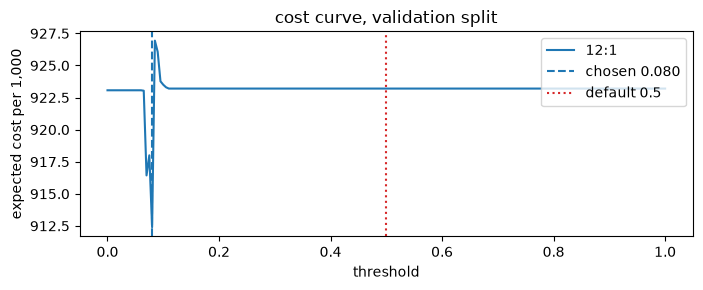

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(curve["threshold"], curve["cost_per_1000"], label=cost.CHALLENGE_MATRIX.name)
ax.axvline(choice.threshold, ls="--", label=f"chosen {choice.threshold:.3f}")
ax.axvline(0.5, ls=":", color="tab:red", label="default 0.5")
ax.set_xlabel("threshold")
ax.set_ylabel("expected cost per 1,000")
ax.legend(loc="upper right")
ax.set_title("cost curve, validation split")
plt.tight_layout()
plt.show()


In [17]:
sensitivity = cost.matrix_sensitivity(val_y, val_proba, [cost.CHALLENGE_MATRIX, cost.FLATTER_MATRIX])
tables.md_table(print(pd.DataFrame(sensitivity)))


  matrix  ratio  threshold  cost_per_1000  cost_per_1000_at_0.5    recall  \
0   12:1   12.0       0.08     912.400000            923.200000  0.255633   
1    4:1    4.0       0.11     307.733333            307.733333  0.000000   

   flag_rate  ties  
0   0.244867     1  
1   0.000000   179  


'|  |\n||'

## ۷. ارزیابی کامل؛ holdout یک‌بار

مدل نهایی روی train+validation برازش می‌شود (آستانه از validation آمده) و آنگاه holdout باز می‌شود - یک بار، بدون بازگشت برای تنظیم دوباره.

In [18]:
combined = pd.concat([splits.train, splits.validation], ignore_index=True)
combined_stats = prep.fit(combined, plan=prep.PLANS[best_plan], columns=kept_inputs)
combined_X = prep.apply(combined, combined_stats)[kept_names]
bundle = models.build_bundle(best.family, combined_X, prep.target(combined), prep_stats=combined_stats, threshold=choice.threshold, matrix=cost.CHALLENGE_MATRIX, seed=SEED, code_version=code_version())
holdout_prepared = prep.apply(splits.holdout, combined_stats)
holdout_proba = bundle.score(holdout_prepared)
holdout_y = prep.target(splits.holdout)
holdout = evaluate.holdout_report(holdout_proba, holdout_y, threshold=bundle.threshold, family=bundle.family, cv=(kept_cv.mean_cost, kept_cv.std_cost))
print(json.dumps(holdout.as_dict(), indent=2, default=str))


{
  "rows": 30000,
  "positives": 2308,
  "threshold": 0.08,
  "family": "logistic",
  "matrix": "12:1",
  "counts": {
    "tp": 466,
    "fp": 5557,
    "tn": 22135,
    "fn": 1842
  },
  "cost_per_1000": 922.033,
  "metrics": {
    "n": 30000.0,
    "positive_rate": 0.076933,
    "accuracy": 0.753367,
    "majority_class_accuracy": 0.923067,
    "precision": 0.07737,
    "recall": 0.201906,
    "f1": 0.111871,
    "specificity": 0.799328,
    "flag_rate": 0.200767
  },
  "undefined_metrics": [],
  "auc": 0.4968,
  "baselines_cost_per_1000": {
    "flag-nobody": 923.2,
    "flag-everybody": 923.067
  },
  "reduction_vs_flagging_nobody_pct": 0.13,
  "cv_mean_cost": 909.9,
  "cv_std_cost": 6.492,
  "cv_holdout_gap": 12.133,
  "matrix_sensitivity": [
    {
      "matrix": "12:1",
      "ratio": 12.0,
      "threshold": 0.085,
      "cost_per_1000": 918.4,
      "cost_per_1000_at_0.5": 923.2,
      "recall": 0.03422876949740035,
      "flag_rate": 0.029433333333333332,
      "ties": 1
   

In [19]:
print(f"confusion matrix at t={bundle.threshold:.4f} on {holdout.rows} held-out rows:")
print(f"| | predicted 1 | predicted 0 |\n|---|---|---|\n"
      f"| actual 1 | {holdout.counts['tp']} | {holdout.counts['fn']} |\n"
      f"| actual 0 | {holdout.counts['fp']} | {holdout.counts['tn']} |")
print(f"\n{evaluate.metrics_table(holdout)}")
print(f"\ncv mean {holdout.cv_mean_cost:.2f} +/- {holdout.cv_std_cost:.2f} vs holdout {holdout.cost_per_1000:.2f}")
print(f"reduction vs flag-nobody: {holdout.reduction_vs_flagging_nobody_pct:.2f}%")


confusion matrix at t=0.0800 on 30000 held-out rows:
| | predicted 1 | predicted 0 |
|---|---|---|
| actual 1 | 466 | 1842 |
| actual 0 | 5557 | 22135 |

| metric | value | why it is not enough alone |
|---|---|---|
| accuracy | 0.7534 | at 12:1 it rewards missing defaults; the trivial answer scores well |
| precision | 0.0774 | silent about the defaults that were not flagged, the expensive half |
| recall | 0.2019 | silent about how many clean applicants were pulled in to catch them |
| f1 | 0.1119 | weights the two errors equally, and this matrix says they are not equal |
| auc | 0.4968 | threshold-free, so it cannot price the operating point actually used |
| flag_rate | 0.2008 | a policy choice shown as a measurement; read it next to cost |

cv mean 909.90 +/- 6.49 vs holdout 922.03
reduction vs flag-nobody: 0.13%


## ۸. اهمیت فیچرها، Model Card، و fairness

اهمیت با permutation روی همان هزینهٔ انتخابی سنجیده می‌شود (نه log-loss)، روی validation - تا holdout فقط یک‌بار مصرف شود.

In [20]:
importance = models.importances(model, val[kept_names], val_y, threshold=choice.threshold, seed=SEED, n_repeats=5)
tables.md_table(print(importance.head(5)))
holdout_flags = (holdout_proba >= bundle.threshold).astype("int64")
bands = evaluate.define_bands(splits.holdout)
fair = evaluate.subgroup_table(splits.holdout.assign(age_band=bands), holdout_y, holdout_flags, holdout_proba)
print(f"\n{tables.md_table(fair)}")
band_rows = json.loads(fair.to_json(orient="records"))
worst_band = max(band_rows, key=lambda row: row["cost_per_1000"])
best_band = min(band_rows, key=lambda row: row["cost_per_1000"])
print(
    f"\nworst band {worst_band['age_band']}: {worst_band['cost_per_1000']:.1f} per 1,000 on "
    f"{worst_band['rows']} rows; best band {best_band['age_band']}: {best_band['cost_per_1000']:.1f}"
)
concentration = evaluate.failure_concentration(holdout_proba, holdout_y, threshold=bundle.threshold)
print(f"\n{json.dumps(concentration, indent=2)}")


                            feature  importance_mean  importance_std
0          delinquency_events_total        14.406667       13.485818
1                    num_late_60_89        14.366667        3.889530
2  income_per_dependent_was_missing        12.820000        2.750644
3        monthly_income_was_missing        12.820000        2.750644
4                        debt_ratio         8.566667        1.601250

| age_band | rows | positive_rate | flag_rate | recall | precision | cost_per_1000 | mean_score |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0-25 | 1987 | 0.074484 | 0.221439 | 0.22973 | 0.077273 | 892.803 | 0.077357 |
| 25-35 | 4940 | 0.071862 | 0.216194 | 0.211268 | 0.070225 | 881.174 | 0.077171 |
| 35-45 | 4961 | 0.077807 | 0.222939 | 0.217617 | 0.075949 | 936.505 | 0.077169 |
| 45-55 | 4848 | 0.07797 | 0.206889 | 0.208995 | 0.078764 | 930.693 | 0.076946 |
| 55-65 | 4935 | 0.078014 | 0.185208 | 0.21039 | 0.088621 | 908.004 | 0.076771 |
| 65+ | 7306 | 0.077881 | 0.184

In [21]:
for line in evaluate.where_it_fails(concentration, fair):
    print(line)
card = evaluate.model_card(
    holdout,
    dataset_line=f"{provenance['file_name']} sha256 {str(provenance['sha256'])[:12]}",
    preparation_line=f"{best_plan}, row-wise half in {credit_cfg.schema}.v_model_input",
    feature_lines=[f"`{name}`" for name in bundle.feature_names],
    trained_rows=len(combined),
    code_version=code_version(),
    intended_use="triage of applications into a human review queue",
    excluded_uses=["adverse pricing decided by the model alone", "populations the file does not represent"],
)
print(card)


1. Applicants the score leaves under the threshold who still default: 1842 of 2308 defaults. Each one costs 12 units, so this slice is the whole argument for moving the threshold down.
2. Weakness at the top of the ranking: the 10% highest scores hold defaults 1.0269x their share, which is far from perfect separation - the model sorts, it does not identify.
3. Uneven cost across groups: age_unreported pays 1037.15 per 1,000 against 881.174 in 25-35, with recall 0.114943 vs 0.211268. A single threshold is a single number applied to populations the model is not equally sure about.
## Model card

| field | value |
|---|---|
| dataset | cs-training.csv sha256 026a9163cc6f |
| rows fitted | 120000 |
| rows held out and looked at once | 30000 |
| preparation | median+indicator, row-wise half in credit.v_model_input |
| family | logistic |
| operating point | score >= 0.0800, cost matrix `12:1` |
| cost per 1,000 (holdout) | 922.03 |
| flag-nobody baseline | 923.20 |
| reduction vs baseline |

## ۹. آرتیفکت‌ها

باندل شامل estimator، ثابت‌های prep و آستانه است؛ اسکریپت پیش‌بینی همین‌ها را مصرف می‌کند، پس مسیر آموزش و مسیر اسکور یک کد تکراری ندارند.

In [22]:
written = bundle.save(Path("data/curated/model"))
print("\n".join(f"{key}: {path}" for key, path in written.items()))
fresh = Path("data/raw/cs-validation.csv")
if fresh.is_file():
    scored = score_file(engine, credit_cfg, fresh, bundle)
    print(f"\n{scored.summary()}")
    tables.md_table(print(scored.scored.head(5)))
else:
    print(f"\nno fresh file to score; run: python -m credit.predict --file <csv> --bundle data/curated/model")


model: data/curated/model/model.joblib
card: data/curated/model/model_card.json
prep: data/curated/model/prep_stats.json

no fresh file to score; run: python -m credit.predict --file <csv> --bundle data/curated/model


## ۱۰. evidence

یک فایل، هر عددی که گزارش مجاز به نقل آن است. ``sort_keys`` اینجا امن است چون مجموعه‌ای از یافته‌هاست (برخلاف ثابت‌های prep که ترتیبشان همان ترتیب ستون‌های فیچر است).

In [23]:
evidence = measure.collect(engine, sql_dir=Path("sql"), schema=credit_cfg.schema, extra={
    "splits": splits.sizes,
    "threshold": {"value": choice.threshold, "grid_size": choice.grid_size, "ties": choice.ties, "cost_per_1000": choice.cost_per_1000},
    "plans": {r.plan: {"mean_cost_per_1000": r.mean_cost} for r in sweep},
    "cv": {r.family: r.as_dict() for r in families},
    "ablation": {"full_cost": full_cost, "dropped": len(dropped), "rows": len(ablation_frame)},
    "prep": {"fitted_rows": combined_stats.fitted_rows, "features": len(kept_names), "input_columns": len(kept_inputs)},
    "holdout": holdout.as_dict(),
    "fairness": {"bands": len(band_rows), "max_band": worst_band, "min_band": best_band},
    "sensitivity": {str(row["matrix"]).replace(":", "_"): row for row in sensitivity},
    "importance": {"count": len(importance)},
})
path = measure.write_json(Path("data/curated/credit_evidence.json"), evidence)
print(report.render_numbers_table(evidence, preferred=["threshold.value", "holdout.cost_per_1000", "splits.train", "prep.fitted_rows"]))
print(f"\nwrote {path}")


| evidence key | value |
|---|---|
| `threshold.value` | 0.08 |
| `holdout.cost_per_1000` | 922.033 |
| `splits.train` | 90000 |
| `prep.fitted_rows` | 120000 |
| `ablation.dropped` | 0 |
| `ablation.full_cost` | 909.9 |
| `ablation.rows` | 6 |
| `cv.boosted_trees.cost_range[0]` | 910.283 |
| `cv.boosted_trees.cost_range[1]` | 921.996 |
| `cv.boosted_trees.folds` | 5 |
| `cv.boosted_trees.mean_auc` | 0.498 |
| `cv.boosted_trees.mean_cost_per_1000` | 916.845 |
| `cv.boosted_trees.per_fold[0].auc` | 0.4933 |
| `cv.boosted_trees.per_fold[0].cost_per_1000` | 921.893 |
| `cv.boosted_trees.per_fold[0].counts.fn` | 1 |
| `cv.boosted_trees.per_fold[0].counts.fp` | 16583 |
| `cv.boosted_trees.per_fold[0].counts.tn` | 33 |
| `cv.boosted_trees.per_fold[0].counts.tp` | 1384 |
| `cv.boosted_trees.per_fold[0].fold` | 1 |
| `cv.boosted_trees.per_fold[0].positives` | 1385 |
| `cv.boosted_trees.per_fold[0].rows` | 18001 |
| `cv.boosted_trees.per_fold[0].threshold` | 0.07 |
| `cv.boosted_trees.per_fold[

In [24]:
status = report.apply_to_file(Path("report.md"), evidence)
print(f"report.md slots filled: {json.dumps(status)}")
print(report.decisions_table(evidence))


report.md slots filled: {"slots": 43, "unresolved": 0, "changed": true, "untraceable": ["\u06f3", "\u06f1", "\u06f0\u06f0\u06f0", "\u06f2\u06f0", "\u06f1\u06f5", "010", "011", "\u06f0\u06f1\u06f1", "\u06f2", "\u06f0\u06f1\u06f0", "\u06f2\u06f5", "\u06f1\u06f2", "\u06f4", "\u06f1\u06f6", "16.2", "\u06f1\u06f5\u06f0", "256", "\u06f0", "\u06f1\u06f5\u06f0\u06f0\u06f0\u06f0", "\u06f2\u06f4", "\u06f8", "\u06f0\u06f8", "\u06f2\u06f0\u06f1", "\u06f5", "\u06f9\u06f1\u06f2", "\u06f4\u06f0", "\u06f9\u06f2\u06f3", "\u06f9\u06f2\u06f2", "\u06f0\u06f3", "\u06f1\u06f3", "\u06f4\u06f9\u06f6\u06f8", "\u06f2\u06f5\u06f9", "\u06f5\u06f0\u06f0", "259", "9009", "28926", "70", "46", "486", "266"]}
| decision | options considered | choice | evidence key |
|---|---|---|---|
| sentinel-policy | ordinary counts - keep them as numbers; codes for a separate state - map to NULL and keep the raw column; data corruption - reject the rows | codes: mapped to NULL in the view, kept verbatim in the table | `queries.sen

## آنچه این نوت‌بوک ادعا نمی‌کند

- یک فایل، یک بازار، یک دورهٔ زمانی؛ تعمیم به جمعیت دیگر ادعا نیست.
- اثر سیاست sentinel بر هزینهٔ واقعیِ بلندمدت (نه بر این ماتریس) اندازه‌گیری نشده.
- اگر ``RUN_LIGHT`` روشن بوده، spread با ۳ فولد گزارش شده و با ۵ فولد قابل مقایسه نیست.
- فیچرهای حذف‌شده در جدول ablation آمده‌اند؛ حذف‌شدن یعنی «در این داده هزینه را کم نکرد»، نه «بی‌معناست».
